<a href="https://colab.research.google.com/github/uw-24-ds-bs-006-source/Northwind-analysis/blob/main/Northwind_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print(">>> Loading real Northwind dataset directly from live GitHub links...")
url_order_details = "https://raw.githubusercontent.com/graphql-compose/graphql-compose-examples/master/examples/northwind/data/csv/order_details.csv"
url_products      = "https://raw.githubusercontent.com/graphql-compose/graphql-compose-examples/master/examples/northwind/data/csv/products.csv"
url_orders        = "https://raw.githubusercontent.com/graphql-compose/graphql-compose-examples/master/examples/northwind/data/csv/orders.csv"
order_details = pd.read_csv(url_order_details)
products      = pd.read_csv(url_products)
orders        = pd.read_csv(url_orders)

print(f"Total Rows Loaded: {len(order_details):,} order lines!")
order_details['gross_revenue'] = order_details['unitPrice'] * order_details['quantity']
order_details['margin_lost']   = order_details['gross_revenue'] * order_details['discount']
summary = order_details.groupby('discount').agg(
    order_lines=('quantity', 'count'),
    avg_quantity=('quantity', 'mean'),
    gross_sales=('gross_revenue', 'sum'),
    margin_lost=('margin_lost', 'sum')
).reset_index()

summary['discount_label'] = (summary['discount'] * 100).astype(int).astype(str) + '%'
summary['avg_quantity']   = summary['avg_quantity'].round(1)
summary['margin_lost']    = summary['margin_lost'].round(2)

print("\n=== RESULTS CALCULATED DYNAMICALLY FROM DATASET ===")
print(summary[['discount_label', 'order_lines', 'avg_quantity', 'margin_lost']])

q_5  = summary.loc[summary['discount'] == 0.05, 'avg_quantity'].values[0]
q_25 = summary.loc[summary['discount'] == 0.25, 'avg_quantity'].values[0]
wasted_heavy = summary.loc[summary['discount'] >= 0.20, 'margin_lost'].sum()

print(f"\nAverage Units at 5% Discount: {q_5} units")
print(f"Average Units at 25% Discount: {q_25} units")
print(f"Volume increase: Only {round(q_25 - q_5, 1)} units extra!")
print(f"Money Wasted on 20%-25% discounts: ${wasted_heavy:,.2f}")

>>> Loading real Northwind dataset directly from live GitHub links...
Total Rows Loaded: 2,155 order lines!

=== RESULTS CALCULATED DYNAMICALLY FROM DATASET ===
   discount_label  order_lines  avg_quantity  margin_lost
0              0%         1317          21.7         0.00
1              1%            1           2.0         0.30
2              2%            2           2.0         1.22
3              3%            3           1.7         3.74
4              4%            1           1.0         3.24
5              5%          185          28.0      7769.34
6              6%            1           2.0         4.08
7             10%          173          25.2     10166.57
8             15%          157          28.4     15442.27
9             20%          161          27.0     22295.28
10            25%          154          28.2     32979.52

Average Units at 5% Discount: 28.0 units
Average Units at 25% Discount: 28.2 units
Volume increase: Only 0.2 units extra!
Money Wasted on 20%-

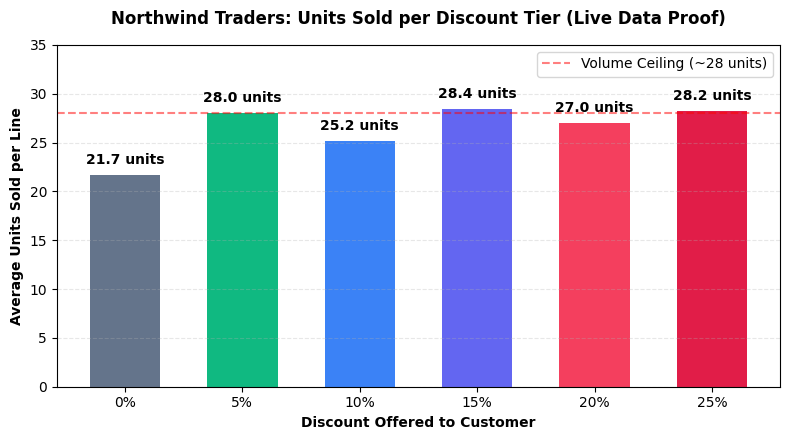

In [ ]:

filtered_summary = summary[summary['order_lines'] > 50].copy()

plt.figure(figsize=(8, 4.5))
colors = ['#64748b', '#10b981', '#3b82f6', '#6366f1', '#f43f5e', '#e11d48']
bars = plt.bar(filtered_summary['discount_label'], filtered_summary['avg_quantity'], color=colors, width=0.6)

plt.title('Northwind Traders: Units Sold per Discount Tier (Live Data Proof)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Discount Offered to Customer', fontweight='bold')
plt.ylabel('Average Units Sold per Line', fontweight='bold')
plt.ylim(0, 35)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, y + 0.8, f"{y} units", ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.axhline(y=28.0, color='red', linestyle='--', alpha=0.5, label='Volume Ceiling (~28 units)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
url_categories = "https://raw.githubusercontent.com/graphql-compose/graphql-compose-examples/master/examples/northwind/data/csv/categories.csv"
categories = pd.read_csv(url_categories)

merged = order_details.merge(products, on='productID').merge(categories, on='categoryID')
merged['gross_revenue'] = merged['unitPrice_x'] * merged['quantity']
merged['discount_lost'] = merged['gross_revenue'] * merged['discount']

category_summary = merged.groupby('categoryName').agg(
    total_sales=('gross_revenue', 'sum'),
    discount_wasted=('discount_lost', 'sum')
).reset_index().sort_values(by='discount_wasted', ascending=False)

category_summary['total_sales'] = category_summary['total_sales'].round(2)
category_summary['discount_wasted'] = category_summary['discount_wasted'].round(2)

print("=== CATEGORY MARGIN EROSION ===")
print(category_summary)

=== CATEGORY MARGIN EROSION ===
     categoryName  total_sales  discount_wasted
0       Beverages    286526.95         18658.77
3  Dairy Products    251330.50         16823.22
5    Meat/Poultry    178188.80         15166.44
7         Seafood    141623.09         10361.35
2     Confections    177099.10          9741.88
1      Condiments    113694.75          7647.66
6         Produce    105268.60          5284.02
4  Grains/Cereals    100726.80          4982.21
